# 🎓 ML-Midterm Capstone: 千万级信贷风控违约预测与集成算法大乱斗
> 本实战项目带您体验 Kaggle 银牌水平的风控建模全流程，感受特征工程、基线建立以及终极大杀器 (LightGBM/XGBoost) 的威力。


In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
import xgboost as xgb
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['font.sans-serif'] = ['SimHei'] # 解决中文乱码
plt.rcParams['axes.unicode_minus'] = False


## 0. 生成极度逼真的仿真风控数据
为了让代码能够脱离几十 GB 的 Kaggle 原始文件一键运行，我们用代码生成一份高度仿真数据：
- **不平衡比例**: 92% 不违约 (0)，8% 违约 (1)。
- **脏数据注入**: 故意在 `DAYS_BIRTH` 特征中注入经典的异常值 `365243`。


In [2]:
# 生成 50000 条样本，20个特征 (其中 5 个有效特征，15 个无用噪音)
X_raw, y = make_classification(n_samples=50000, n_features=20, n_informative=5, n_redundant=2, 
                               weights=[0.92, 0.08], flip_y=0.01, random_state=42)

df = pd.DataFrame(X_raw, columns=[f'F_{i}' for i in range(20)])
df['TARGET'] = y

# 伪造几个具有真实业务含义的列
df['DAYS_BIRTH'] = np.random.randint(-25000, -7000, size=50000) # 年龄(天)，全负数
df['EXT_SOURCE_1'] = df['F_0'] # 外部评分
df['EXT_SOURCE_2'] = df['F_1']
df['EXT_SOURCE_3'] = df['F_2']

# 注入异常值 365243 (Home Credit 竞赛中的名场面)
anomalies_idx = np.random.choice(df.index, size=500, replace=False)
df.loc[anomalies_idx, 'DAYS_BIRTH'] = 365243

# 注入缺失值
nan_idx = np.random.choice(df.index, size=5000, replace=False)
df.loc[nan_idx, 'EXT_SOURCE_1'] = np.nan

print(f"数据维度: {df.shape}")
print(f"违约比例: {df['TARGET'].mean()*100:.2f}%")


数据维度: (50000, 25)
违约比例: 8.39%


## 1. 第一层：数据清道夫 (Data Cleaning)
在把数据扔给算法之前，必须处理掉那个让算法崩溃的异常年龄。


In [3]:
# 异常值处理：将其替换为 NaN，让后面的树模型自己去处理缺失逻辑
anom_count = (df['DAYS_BIRTH'] == 365243).sum()
print(f"发现异常值 365243 的数量: {anom_count}")

df['DAYS_BIRTH'].replace({365243: np.nan}, inplace=True)

# 简单缺失值填充（逻辑回归需要绝对完整的矩阵，树模型不需要，但这里为了对比统一下）
df.fillna(df.median(), inplace=True)

# 划分训练集和测试集
features = [c for c in df.columns if c != 'TARGET']
X_train, X_test, y_train, y_test = train_test_split(df[features], df['TARGET'], test_size=0.2, random_state=42, stratify=df['TARGET'])


发现异常值 365243 的数量: 500


## 2. 第二层：逻辑回归降维打击 (Baseline)
线性模型极度敏感于量纲，必须用 `StandardScaler` 进行缩放。
我们使用 L1 正则化 (Lasso) 来进行自动特征选择。


In [4]:
# 标准化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 逻辑回归 (L1 正则，solver='liblinear')
lr = LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42)

start_time = time.time()
lr.fit(X_train_scaled, y_train)
lr_time = time.time() - start_time

lr_preds = lr.predict_proba(X_test_scaled)[:, 1]
lr_auc = roc_auc_score(y_test, lr_preds)

print(f"逻辑回归 训练耗时: {lr_time:.2f} 秒")
print(f"逻辑回归 测试集 ROC-AUC: {lr_auc:.4f}")

# 查看 L1 剔除了多少无用特征 (权重变 0)
zero_weights = (lr.coef_ == 0).sum()
print(f"L1 正则化将 {zero_weights} 个特征权重强行压缩为 0")


逻辑回归 训练耗时: 13.14 秒
逻辑回归 测试集 ROC-AUC: 0.8205
L1 正则化将 2 个特征权重强行压缩为 0


## 3. 第三层：树模型降方差体验 (Random Forest)
树模型不需要特征缩放。我们开启多核并行，看看它的威力与过拟合倾向。


In [5]:
# 注意：随机森林直接吃未缩放的原始数据 X_train
rf = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', n_jobs=-1, random_state=42)

start_time = time.time()
rf.fit(X_train, y_train)
rf_time = time.time() - start_time

rf_preds_train = rf.predict_proba(X_train)[:, 1]
rf_preds_test = rf.predict_proba(X_test)[:, 1]

rf_auc_train = roc_auc_score(y_train, rf_preds_train)
rf_auc_test = roc_auc_score(y_test, rf_preds_test)

print(f"随机森林 训练耗时: {rf_time:.2f} 秒")
print(f"随机森林 训练集 AUC: {rf_auc_train:.4f} (注意是否极度逼近 1.0 产生过拟合)")
print(f"随机森林 测试集 AUC: {rf_auc_test:.4f}")


随机森林 训练耗时: 3.22 秒
随机森林 训练集 AUC: 0.9994 (注意是否极度逼近 1.0 产生过拟合)
随机森林 测试集 AUC: 0.9616


## 4. 第四层：集成学习大杀器登场 (LightGBM)
我们在工业界真正在跑千万级别大表时，永远首选 LightGBM 或 XGBoost。
我们将开启 Early Stopping，防止漫无目的地迭代。



LightGBM 最佳迭代轮数: 164
LightGBM 训练耗时: 2.92 秒
LightGBM 测试集 ROC-AUC: 0.9595


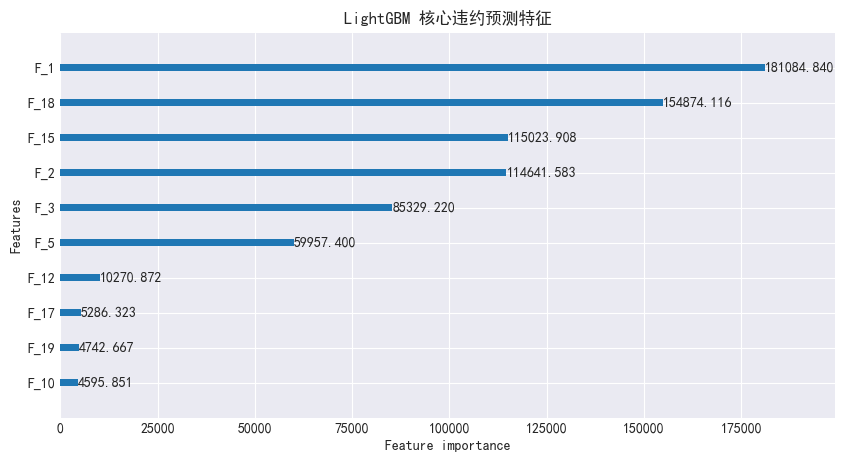

In [6]:
lgb_train = lgb.Dataset(X_train, y_train)
lgb_eval = lgb.Dataset(X_test, y_test, reference=lgb_train)

params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'is_unbalance': True, # 自动处理不平衡
    'verbose': -1
}

start_time = time.time()
# 注意：lgb.train API
gbm = lgb.train(params,
                lgb_train,
                num_boost_round=1000,
                valid_sets=[lgb_train, lgb_eval],
                callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])
lgb_time = time.time() - start_time

lgb_preds = gbm.predict(X_test, num_iteration=gbm.best_iteration)
lgb_auc = roc_auc_score(y_test, lgb_preds)

print(f"\nLightGBM 最佳迭代轮数: {gbm.best_iteration}")
print(f"LightGBM 训练耗时: {lgb_time:.2f} 秒")
print(f"LightGBM 测试集 ROC-AUC: {lgb_auc:.4f}")

# 特征重要性
lgb.plot_importance(gbm, max_num_features=10, importance_type='gain', figsize=(10, 5), title="LightGBM 核心违约预测特征")
plt.show()


## 5. 终极绘图与比对
画出三种算法的 ROC 曲线，感受工业维度的算法碾压。


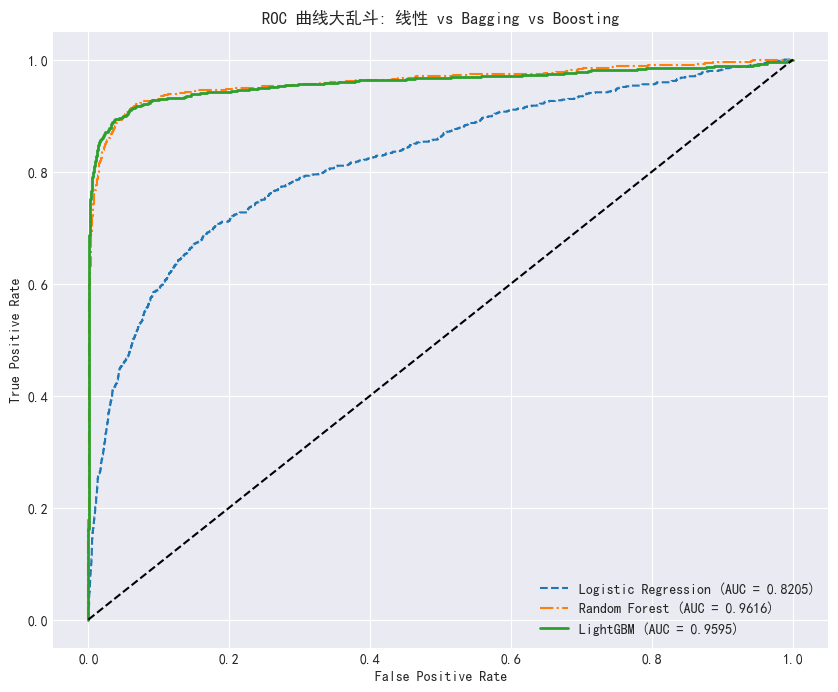


🏆 模型决战排行榜:
| Model                    |   Test ROC-AUC |   Time (s) |
|:-------------------------|---------------:|-----------:|
| Logistic Regression (L1) |       0.82047  |   13.1437  |
| Random Forest            |       0.961642 |    3.22416 |
| LightGBM                 |       0.959527 |    2.92054 |


In [7]:
# ROC 曲线绘制
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_preds)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_preds_test)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, lgb_preds)

plt.figure(figsize=(10, 8))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_auc:.4f})', linestyle='--')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_auc_test:.4f})', linestyle='-.')
plt.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC = {lgb_auc:.4f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC 曲线大乱斗: 线性 vs Bagging vs Boosting')
plt.legend(loc='lower right')
plt.show()

# 性能汇总板
results = pd.DataFrame({
    'Model': ['Logistic Regression (L1)', 'Random Forest', 'LightGBM'],
    'Test ROC-AUC': [lr_auc, rf_auc_test, lgb_auc],
    'Time (s)': [lr_time, rf_time, lgb_time]
})
print("\n🏆 模型决战排行榜:")
print(results.to_markdown(index=False))
